# Tomografía de primeras llegadas: inversión de rayos rectos retenidos

**Nivel 2 — Métodos inversos aplicados** · 60–75 min · álgebra lineal y mínimos cuadrados

## Objetivos
Construir una matriz de longitudes de rayo para llegadas crosshole sintéticas; resolver una inversa 2D regularizada de lentitud con fuentes de entrenamiento; comparar baseline homogéneo e inversa en profundidades completas retenidas; inspeccionar cobertura y no unicidad.

## Preparación

Ejecute desde la raíz en el entorno fijado:
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8

La celda experimental imprime las versiones activas.

## Datos
Todas las llegadas se generan determinísticamente en memoria. Son datos crosshole sintéticos, no del levantamiento Koenigsee. data-pipeline/traveltime.py implementa aparte parseo/QC estricto .sgt e inversión pyGIMLi condicional; los bytes de fuente no están incluidos, por lo que este capítulo no fabrica ni sustituye observaciones de terreno.

## Método

Para trayectoria fija Γᵢ, el tiempo de primera llegada es tᵢ=∫Γᵢ s(x,z)dl, con lentitud s=1/v en s/m. Al discretizar celdas se obtiene t≈A s; Aᵢⱼ es la longitud en metros del rayo i dentro de la celda j. Es lineal en lentitud solo con geometría recta fija. Omite curvatura, topología de refracción, anisotropía y efectos de frecuencia finita.

Estimamos lentitud homogénea s₀ con entrenamiento únicamente y resolvemos q=(s−s₀)/(1/3000 s/m), adimensional, minimizando ||W(A s₀ + A s_scale q − t)||² + λ||Dq||². W=1/σt y D es un operador de diferencias primeras entre vecinas. Se retienen profundidades completas de fuente; los tiempos retenidos no definen s₀, inversión, λ ni selección del modelo. RMSE/WRMS retenidos son diagnósticos posteriores.

M09 del producto en data-pipeline/traveltime.py valida geometría y picks .sgt atribuidos, conserva banderas de anomalía, crea particiones por disparo completo y ejecuta inversión no lineal pyGIMLi en malla congelada. Sus datos de terreno no están incluidos. Este notebook es un complemento lineal sintético, no un replay ni proxy de aquella ruta.

### Preguntas
1. ¿Dónde escasean conteos o ángulos de rayo y qué celdas son menos identificables?
2. ¿La inversa mejora error retenido frente al baseline homogéneo?
3. ¿Qué cambia al curvar rayos y reconstruir iterativamente la matriz?

### Experimento 2 — varíe ruido y suavidad, luego ajuste

Cambie RAY_NOISE_S y LAMBDA_SMOOTH. Una semilla fija reproduce el ruido agregado a picks. Retenga profundidades completas de fuente, no filas aleatorias de rayos.

In [1]:
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'scipy', 'matplotlib']})
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix, vstack
from scipy.sparse.linalg import lsqr

# Levantamiento crosshole sintético: pozos verticales; coordenadas en metros.
nx, nz = 12, 6
dx = dz = 500.0
x_edges = np.arange(nx+1)*dx
z_edges = np.arange(nz+1)*dz
x_src = np.zeros(12); z_src = (np.arange(12)+0.5)*250.0
x_rec = np.full(12, nx*dx); z_rec = (np.arange(12)+0.5)*250.0
# Verdad sintética conocida; nunca se entrega a la inversa.
velocity_true = np.full((nz,nx), 2600.0)
velocity_true[2:,:] = 3600.0
velocity_true[1:5,5:8] = 2050.0
slowness_true = 1.0/velocity_true
src_ids, rec_ids = np.meshgrid(np.arange(12),np.arange(12),indexing='ij')
src_ids, rec_ids = src_ids.ravel(), rec_ids.ravel()
n_rays = len(src_ids)
rows, cols, lengths = [], [], []
for i,(si,ri) in enumerate(zip(src_ids,rec_ids)):
    x0,z0,x1,z1 = x_src[si],z_src[si],x_rec[ri],z_rec[ri]
    distance = np.hypot(x1-x0,z1-z0)
    n_sample = 5000
    u = (np.arange(n_sample)+.5)/n_sample
    xs = x0+u*(x1-x0); zs = z0+u*(z1-z0)
    ix = np.clip(np.searchsorted(x_edges,xs,side='right')-1,0,nx-1)
    iz = np.clip(np.searchsorted(z_edges,zs,side='right')-1,0,nz-1)
    cells, counts = np.unique(iz*nx+ix,return_counts=True)
    rows.extend([i]*len(cells)); cols.extend(cells.tolist())
    lengths.extend((counts*distance/n_sample).tolist())
A = csr_matrix((lengths,(rows,cols)),shape=(n_rays,nx*nz))
RAY_NOISE_S = 0.0005
SEED = 60427
sigma_t = RAY_NOISE_S
rng = np.random.default_rng(SEED)
t_obs = A@slowness_true.ravel()+rng.normal(0,sigma_t,n_rays)
# Se retienen profundidades completas de fuente; política fijada antes de examinar tiempos.
held_sources = np.array([1,4,7,10])
held = np.isin(src_ids,held_sources); train = ~held
assert train.any() and held.any()
distance = np.asarray(A.sum(axis=1)).ravel()
s0 = float(np.dot(distance[train],t_obs[train])/np.dot(distance[train],distance[train]))
scale_s = 1/3000.0
Atr = A[train]
G = Atr*scale_s/sigma_t
rhs = (t_obs[train]-Atr@np.full(nx*nz,s0))/sigma_t
pairs=[]
for iz in range(nz):
    for ix in range(nx):
        j=iz*nx+ix
        if ix+1<nx: pairs.append((j,j+1))
        if iz+1<nz: pairs.append((j,j+nx))
rr=[]; cc=[]; vv=[]
for k,(a,b) in enumerate(pairs):
    rr.extend([k,k]); cc.extend([a,b]); vv.extend([-1.,1.])
D=csr_matrix((vv,(rr,cc)),shape=(len(pairs),nx*nz))
LAMBDA_SMOOTH=0.45
system=vstack([G,np.sqrt(LAMBDA_SMOOTH)*D],format='csr')
q=lsqr(system,np.r_[rhs,np.zeros(D.shape[0])],atol=1e-10,btol=1e-10,iter_lim=400)[0]
slowness_est=s0+scale_s*q
velocity_est=1/slowness_est.reshape(nz,nx)
pred=np.asarray(A@slowness_est).ravel()
base=distance*s0

def score(prediction,mask):
    residual=prediction[mask]-t_obs[mask]
    return {'n':int(mask.sum()),'RMSE_ms':float(np.sqrt(np.mean(residual**2))*1000),
            'WRMS':float(np.sqrt(np.mean((residual/sigma_t)**2)))}
table=pd.DataFrame([
 {'modelo':'homogéneo, solo entrenamiento',**score(base,train),
  **{f'heldout_{k}':v for k,v in score(base,held).items()}},
 {'modelo':'lentitud lineal + suavidad',**score(pred,train),
  **{f'heldout_{k}':v for k,v in score(pred,held).items()}}
])
display(table.round(3))
print({'rayos':n_rays,'entrenamiento':int(train.sum()),'retenidos':int(held.sum()),
       'índices_fuente_retenidos':held_sources.tolist(),'velocidad_baseline_m_s':1/s0,
       'lambda':LAMBDA_SMOOTH,'sigma_ruido_ms':sigma_t*1000,
       'solver':'SciPy LSQR on weighted ray lengths with first-difference penalty'})

heldout_wrms = score(pred, held)['WRMS']
print('WRMS retenido:', round(heldout_wrms,3), 'frente al objetivo de ruido unitario 1.0.')
if heldout_wrms > 1:
    print('El residual excede la escala de ruido supuesta: el ajuste predictivo no es consistente con ese ruido, aunque mejore frente al baseline.')
else:
    print('El residual queda dentro de la escala de ruido supuesta para esta partición sintética; no valida datos de terreno.')


Runtime versions: {'numpy': '2.2.6', 'scipy': '1.15.2', 'matplotlib': '3.10.8'}


,modelo,n,RMSE_ms,WRMS,heldout_n,heldout_RMSE_ms,heldout_WRMS
0,"homogéneo, solo entrenamiento",96,178.725,357.450,48,173.868,347.736
1,lentitud lineal + suavidad,96,0.279,0.558,48,2.796,5.591


{'rayos': 144, 'entrenamiento': 96, 'retenidos': 48, 'índices_fuente_retenidos': [1, 4, 7, 10], 'velocidad_baseline_m_s': 2859.842394276743, 'lambda': 0.45, 'sigma_ruido_ms': 0.5, 'solver': 'SciPy LSQR on weighted ray lengths with first-difference penalty'}
WRMS retenido: 5.591 frente al objetivo de ruido unitario 1.0.
El residual excede la escala de ruido supuesta: el ajuste predictivo no es consistente con ese ruido, aunque mejore frente al baseline.


### Diagnóstico 2 — compare modelo, cobertura y puntajes retenidos

El panel de cobertura cuenta longitud total de trayectorias por celda; no es matriz de resolución. Alta cobertura no demuestra información angular independiente ni recuperación única.

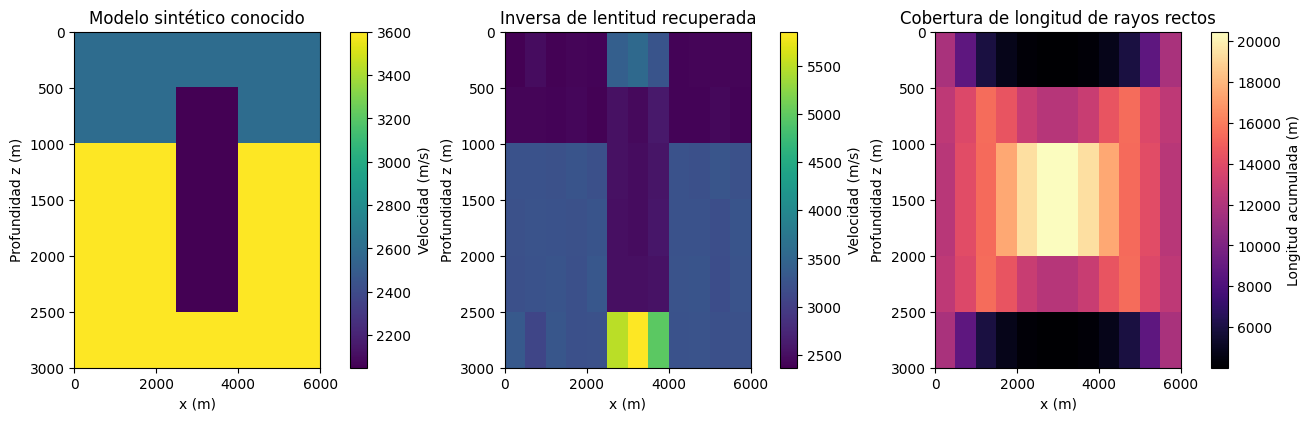

RMSE de velocidad frente a verdad sintética: 534.2767919227546 m/s
Las llegadas retenidas no seleccionaron lambda ni el modelo.


In [2]:
# Reproducible notebook experiment cell.
coverage=np.asarray(A.T@np.ones(n_rays)).reshape(nz,nx)
fig,axes=plt.subplots(1,3,figsize=(13,4.1),constrained_layout=True)
extent=[0,nx*dx,nz*dz,0]
for ax,model,title in zip(axes[:2],[velocity_true,velocity_est],
                          ['Modelo sintético conocido','Inversa de lentitud recuperada']):
    im=ax.imshow(model,extent=extent,aspect='auto',cmap='viridis')
    ax.set(title=title,xlabel='x (m)',ylabel='Profundidad z (m)')
    fig.colorbar(im,ax=ax,label='Velocidad (m/s)')
im=axes[2].imshow(coverage,extent=extent,aspect='auto',cmap='magma')
axes[2].set(title='Cobertura de longitud de rayos rectos',xlabel='x (m)',ylabel='Profundidad z (m)')
fig.colorbar(im,ax=axes[2],label='Longitud acumulada (m)')
plt.show()
print('RMSE de velocidad frente a verdad sintética:',float(np.sqrt(np.mean((velocity_est-velocity_true)**2))),'m/s')
print('Las llegadas retenidas no seleccionaron lambda ni el modelo.')


## Resultados

Lea RMSE/WRMS de entrenamiento y retención en la tabla, y RMSE de velocidad en el gráfico. Compare WRMS calculado con el objetivo unitario. Un valor mayor que uno excede la escala de ruido de picks supuesta, aunque mejore el baseline. No reajuste usando llegadas retenidas.

## Resumen
Registre ambos puntajes retenidos, partición por fuente completa, prior de suavidad y una limitación de cobertura de rayos rectos.

## Referencias
- [Ejemplo pyGIMLi Koenigsee de primeras llegadas](https://www.pygimli.org/_examples_auto/2_seismics/plot_04_koenigsee/)
- [Marco de inversión pyGIMLi](https://www.pygimli.org/user-guide/inversion/)
- Parser, QC e inversa M09: data-pipeline/traveltime.py
- Experimento sintético generado en memoria, no datos de terreno.